# Projet final : classification d'émotions

Le but du projet est de prédire l'émotion d'un texte court en anglais (du type tweet) parmi 6 émotions : sadness, joy, love, anger, fear et surprise.

On compare plusieurs modèles vus en cours, puis on garde le meilleur pour l'utiliser dans une webapp : l'utilisateur écrit un texte et l'application lui renvoie l'émotion prédite avec sa probabilité.

In [41]:
# installation de la librairie datasets (Hugging Face) qui sert à télécharger le dataset Emotion
%pip install datasets

In [42]:
from datasets import load_dataset

ds = load_dataset("dair-ai/emotion", "unsplit")

ds

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 416809
    })
})

In [43]:
label_names = ds["train"].features["label"].names

label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [44]:
import pandas as pd

df = ds["train"].to_pandas()

print(df.shape)
df.head()

(416809, 2)


,text,label
0,i feel awful about it too because it s my job ...,0
1,im alone i feel awful,0
2,ive probably mentioned this before but i reall...,1
3,i was feeling a little low few days back,0
4,i beleive that i am much more sensitive to oth...,2


In [45]:
df["emotion"] = df["label"].apply(lambda x: label_names[x])

df.head()

,text,label,emotion
0,i feel awful about it too because it s my job ...,0,sadness
1,im alone i feel awful,0,sadness
2,ive probably mentioned this before but i reall...,1,joy
3,i was feeling a little low few days back,0,sadness
4,i beleive that i am much more sensitive to oth...,2,love


## Analyse du dataset

On utilise la version "unsplit" du dataset Emotion, qui contient environ 416 000 tweets. On l'a préférée à la version standard (environ 20 000 tweets) parce que dans la version standard, la classe surprise n'avait que 565 exemples dans le train, alors qu'il en faudrait idéalement environ 1000 par classe pour limiter le sur-apprentissage des réseaux de neurones.

Avant de découper le dataset en train / validation / test, on regarde à quoi ressemblent les données : valeurs manquantes, doublons, répartition des émotions et longueur des textes.

In [46]:
df.isna().sum()

,0
text,0
label,0
emotion,0


In [47]:
df.duplicated(subset="text").sum()

np.int64(22987)

In [48]:
doublons = df[df.duplicated(subset="text", keep=False)]

nb_labels = doublons.groupby("text")["label"].nunique()

nb_labels.value_counts()

,count
label,
2,22290
1,522
3,4
4,1


In [49]:
print("avant :", len(df))

df = df.drop_duplicates(subset="text", keep=False)

print("après :", len(df))

avant : 416809
après : 371005


On a d'abord vérifié la qualité des données. Il n'y a aucune valeur manquante, par contre il y a 22 987 doublons, soit environ 5,5 % du dataset.

En regardant ces doublons de plus près, on voit que sur les 22 817 textes concernés, 22 295 ont plusieurs labels différents : le même tweet est classé avec 2, 3 ou même 4 émotions. Seulement 522 textes sont en double avec la même émotion. Une explication possible est que le dataset a été annoté automatiquement à partir des hashtags : un tweet avec plusieurs hashtags d'émotions différentes aurait été enregistré une fois par émotion. On n'a pas pu le vérifier, c'est une hypothèse.

On a décidé de supprimer tous les exemplaires de chaque texte en double. Garder les doublons contradictoires reviendrait à apprendre au modèle deux réponses différentes pour la même phrase, et n'en garder qu'un voudrait dire choisir un label au hasard. On perd 45 804 lignes (environ 11 % du dataset), mais il reste 371 005 tweets, ce qui est largement suffisant.

In [50]:
df["emotion"].value_counts()

,count
emotion,
joy,129165
sadness,115868
anger,52262
fear,39554
love,24335
surprise,9821


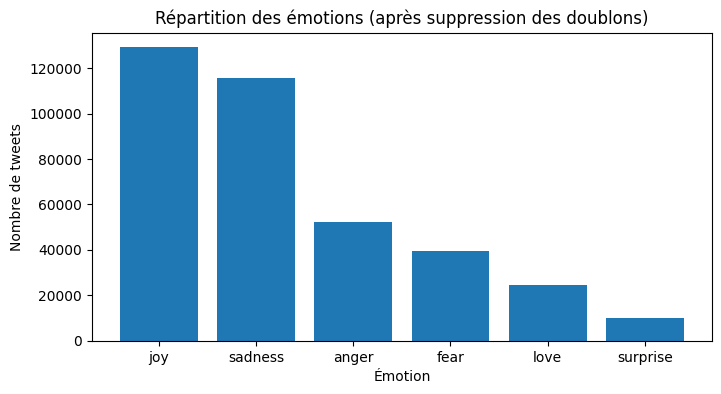

In [51]:
import matplotlib.pyplot as plt

counts = df["emotion"].value_counts()

plt.figure(figsize=(8, 4))
plt.bar(counts.index, counts.values)
plt.title("Répartition des émotions (après suppression des doublons)")
plt.xlabel("Émotion")
plt.ylabel("Nombre de tweets")
plt.show()

Après suppression des doublons, il reste 371 005 tweets. Le dataset est toujours déséquilibré : joy (34,8 %) et sadness (31,2 %) représentent les 2/3 des données, alors que surprise n'en représente que 2,6 % (9 821 tweets), soit environ 13 fois moins que joy.

Par contre, toutes les classes ont maintenant largement plus de 1000 exemples, ce qui était la raison de passer à la grande version.

On remarque aussi que surprise a perdu plus d'un tiers de ses tweets avec la suppression des doublons, beaucoup plus que les autres classes. Ça veut dire que les tweets surprise étaient souvent aussi étiquetés avec une autre émotion, ce qui est logique (une surprise peut être bonne ou mauvaise). On peut s'attendre à ce que ce soit la classe la plus difficile à prédire.

Pour gérer ce déséquilibre, on va sous-échantillonner les classes les plus grandes dans le jeu d'entraînement, pour que chaque émotion ait le même nombre d'exemples. On utilisera aussi le F1-score macro pour comparer les modèles, car il donne le même poids à chaque émotion.

In [52]:
df["nb_mots"] = df["text"].str.split().str.len()

df["nb_mots"].describe()

,nb_mots
count,371005.000000
mean,19.156804
std,11.039092
min,1.000000
25%,11.000000
50%,17.000000
75%,25.000000
max,178.000000


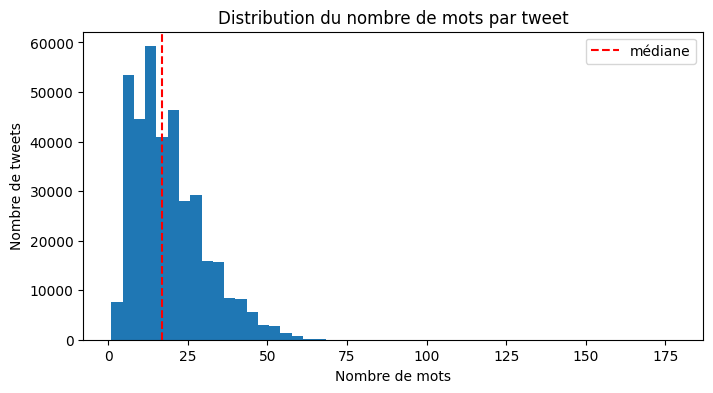

In [53]:
plt.figure(figsize=(8, 4))
plt.hist(df["nb_mots"], bins=50)
plt.axvline(df["nb_mots"].median(), color="red", linestyle="--", label="médiane")
plt.title("Distribution du nombre de mots par tweet")
plt.xlabel("Nombre de mots")
plt.ylabel("Nombre de tweets")
plt.legend()
plt.show()

In [54]:
courts = df[df["nb_mots"] <= 2]

print(len(courts))
courts.head(20)

72


,text,label,emotion,nb_mots
37,article published,1,joy,2
9752,my sister,0,sadness,2
16572,before examination,4,fear,2
18633,last year,0,sadness,2
27587,a child,0,sadness,2
35218,at night,4,fear,2
35352,no description,3,anger,2
43237,summer,0,sadness,1
45779,salo,3,anger,1
49070,failing examn,0,sadness,2


In [55]:
print("avant :", len(df))

df = df[df["nb_mots"] > 2]

print("après :", len(df))

avant : 371005
après : 370933


In [56]:
longs = df[df["nb_mots"] > 100]

print(len(longs))
longs.sort_values("nb_mots", ascending=False).head(10)

3


,text,label,emotion,nb_mots
369479,a few days back i was waiting for the bus at t...,3,anger,178
206503,two years back someone invited me to be the tu...,3,anger,110
103972,i have been thinking of changing my major for ...,0,sadness,101


Les textes sont courts : 19 mots en moyenne et une médiane de 17 mots. 75 % des tweets font 25 mots ou moins, et presque aucun ne dépasse 65 mots. La moyenne est un peu au-dessus de la médiane à cause de quelques textes très longs (jusqu'à 178 mots).

Pour les textes très courts, on a regardé les tweets de 2 mots ou moins. Il y en a 72, et la plupart sont des fragments sans sens ("when i", "after my", "a child") avec des labels incohérents ("summer" classé sadness, "in august" classé joy). On les a supprimés car ils ajoutent du bruit sans rien apprendre au modèle. Il reste 370 933 textes.

Pour les textes très longs, seulement 3 dépassent 100 mots. Ce sont des vrais textes qui ont du sens (des petits récits personnels) avec des labels plausibles. On a décidé de les garder, car ils ne sont pas du bruit, juste plus longs que la moyenne.

On remarque aussi que certains textes, courts ou longs, ressemblent plus à des réponses à un questionnaire ou à des récits qu'à des tweets ("before examination", "no description", "two years back someone invited me..."). Une partie du dataset vient peut-être d'une autre source que Twitter.

Comme les textes sont courts, on conseillera dans la webapp d'écrire une phrase courte en anglais, puisque c'est sur ce type de texte que le modèle a été entraîné.

## Découpage train / validation / test

La version "unsplit" n'est pas découpée, donc on fait la séparation nous-mêmes : 80 % pour le train, qui sert à entraîner les modèles, 10 % pour la validation, qui sert à les comparer et à choisir le meilleur, et 10 % pour le test, qu'on utilise une seule fois à la fin pour évaluer le modèle retenu sur des données jamais vues.

On a pris 80/10/10 plutôt que 60/20/20 parce que le dataset est très gros : 10 % représente déjà plus de 37 000 tweets, ce qui suffit largement pour évaluer, et on garde plus de données pour l'entraînement.

Le découpage est stratifié, c'est-à-dire qu'on garde la même proportion de chaque émotion dans les trois jeux. On ne sous-échantillonne le train qu'après le découpage : la validation et le test gardent la vraie répartition des émotions, pour que l'évaluation corresponde à ce que le modèle rencontrera en vrai.

In [57]:
from sklearn.model_selection import train_test_split

train_df, reste_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df["label"],
    random_state=42
)

print("train :", len(train_df))
print("reste :", len(reste_df))

train : 296746
reste : 74187


In [58]:
val_df, test_df = train_test_split(
    reste_df,
    test_size=0.5,
    stratify=reste_df["label"],
    random_state=42
)

print("validation :", len(val_df))
print("test :", len(test_df))

validation : 37093
test : 37094


In [59]:
proportions = pd.DataFrame({
    "train": train_df["emotion"].value_counts(normalize=True),
    "validation": val_df["emotion"].value_counts(normalize=True),
    "test": test_df["emotion"].value_counts(normalize=True),
})

(proportions * 100).round(2)

,train,validation,test
emotion,,,
joy,34.82,34.82,34.82
sadness,31.23,31.23,31.23
anger,14.08,14.08,14.08
fear,10.66,10.66,10.66
love,6.56,6.56,6.56
surprise,2.65,2.65,2.65


Après le découpage, on a 296 746 textes dans le train, 37 093 dans la validation et 37 094 dans le test. On a mis random_state=42 pour que le découpage soit le même à chaque fois qu'on relance le notebook.

Le tableau des proportions montre que la stratification a bien marché : chaque émotion a exactement le même pourcentage dans les trois jeux (par exemple 34,82 % de joy et 2,65 % de surprise partout).

In [60]:
train_df["emotion"].value_counts()

,count
emotion,
joy,103323
sadness,92679
anger,41789
fear,31630
love,19468
surprise,7857


In [61]:
plafond = 20000
morceaux = []

for emotion in label_names:
    tweets_emotion = train_df[train_df["emotion"] == emotion]
    n = min(len(tweets_emotion), plafond)
    morceaux.append(tweets_emotion.sample(n=n, random_state=42))

train_equilibre = pd.concat(morceaux)

print(len(train_equilibre))

107325


In [62]:
train_equilibre = train_equilibre.sample(frac=1, random_state=42)

train_equilibre.head(10)

,text,label,emotion,nb_mots
356845,i feel rather triumphant actually like neener ...,1,joy,25
114723,i park it back there and i cant tell you what ...,4,fear,25
317650,i want to keep my brain away from being draine...,2,love,17
29863,i feel like a productive person rather than a ...,1,joy,12
109778,i feel they so selfish,3,anger,5
72422,i feel fond and protective of it,2,love,7
79754,i feel that my blog is my only place where i c...,2,love,21
218414,i feel if they really are keen to get it they ...,1,joy,13
144784,i feel funny about writing about our life as o...,5,surprise,11
92175,i feel badly for susan with so many unkind thi...,3,anger,14


In [63]:
train_equilibre["emotion"].value_counts()

,count
emotion,
joy,20000
fear,20000
anger,20000
sadness,20000
love,19468
surprise,7857


Dans le train, les émotions sont toujours très déséquilibrées : joy a 103 323 tweets alors que surprise n'en a que 7 857, soit environ 13 fois moins.

Pour réduire cet écart, on a sous-échantillonné le train : pour chaque émotion on garde au maximum 20 000 tweets tirés au hasard, et les émotions qui en ont moins (love et surprise) gardent tous les leurs. On a hésité avec un plafond de 7 857, le nombre de surprise, qui aurait donné des classes parfaitement équilibrées. Mais il ne serait resté que 47 142 tweets, soit 84 % du train en moins. Avec 20 000, on garde 107 325 tweets et surprise n'a plus qu'environ 2,5 fois moins d'exemples que les autres au lieu de 13. Le déséquilibre qui reste sera compensé avec des poids de classes (class_weight="balanced") dans les modèles qui le permettent.

Après le sous-échantillonnage, les tweets étaient rangés par émotion, donc on les a mélangés. Sinon un réseau de neurones, qui apprend par petits paquets, verrait des milliers de tweets de la même émotion à la suite.

Le train équilibré contient 20 000 tweets pour joy, sadness, anger et fear, 19 468 pour love et 7 857 pour surprise. La validation et le test ne sont pas touchés.

### Récapitulatif des données

| Étape | Nombre de textes |
|---|---|
| Dataset de départ (version unsplit) | 416 809 |
| Après suppression des doublons | 371 005 (- 45 804) |
| Après suppression des textes de 2 mots ou moins | 370 933 (- 72) |
| Train (80 %) | 296 746 |
| Validation (10 %) | 37 093 |
| Test (10 %) | 37 094 |
| Train après sous-échantillonnage | 107 325 |

On a 6 catégories : sadness, joy, love, anger, fear et surprise.

Les modèles seront entraînés sur le train sous-échantillonné (107 325 textes), comparés sur la validation, et le modèle retenu sera évalué une seule fois sur le test.

## Modèles de Machine Learning

On compare trois modèles vus en cours. Naive Bayes est un modèle probabiliste qui apprend, pour chaque émotion, la probabilité d'apparition de chaque mot. Il est très rapide et souvent utilisé en premier pour du texte. Le SVM cherche les frontières qui séparent le mieux les émotions entre elles. Le KNN classe un texte en regardant l'émotion des textes du train qui lui ressemblent le plus, c'est simple à comprendre mais ça peut être lent.

Ces modèles ne savent pas lire du texte, ils ont besoin de nombres. On transforme donc d'abord chaque tweet en vecteur avec un TF-IDF, et les trois modèles utilisent exactement les mêmes vecteurs pour que la comparaison soit équitable.

Pour comparer les modèles, on regarde surtout le F1-score macro sur la validation. L'accuracy seule serait trompeuse : la validation garde la vraie répartition, donc un modèle qui raterait toutes les surprises ne perdrait que 2,6 points d'accuracy. Le F1 macro calcule un score par émotion puis fait la moyenne, donc chaque émotion compte autant.

In [64]:
X_train = train_equilibre["text"]
y_train = train_equilibre["label"]

X_val = val_df["text"]
y_val = val_df["label"]

X_test = test_df["text"]
y_test = test_df["label"]

print(len(X_train), len(X_val), len(X_test))

107325 37093 37094


In [65]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2)

### Vectorisation avec TF-IDF

Le TF-IDF construit d'abord un vocabulaire avec tous les mots du train, et chaque mot devient une colonne. Pour chaque tweet, il compte combien de fois chaque mot apparaît (TF), puis il multiplie par un poids (IDF) qui dépend du nombre de tweets qui contiennent ce mot. Un mot présent presque partout comme "i" ou "feel" a un poids faible, alors qu'un mot plus rare comme "furious" ou "terrified" a un poids fort. Chaque tweet devient donc un vecteur où les mots qui le caractérisent ont les valeurs les plus fortes. Comme un tweet ne fait qu'une vingtaine de mots, presque toutes les valeurs sont à 0.

On a mis ngram_range=(1, 2) pour prendre les mots seuls mais aussi les paires de mots qui se suivent. Ça permet de garder des expressions comme "not happy", qui n'ont pas le même sens que "happy" tout seul. Avec min_df=2, on ignore les mots qui n'apparaissent que dans un seul tweet (souvent des fautes de frappe), ce qui réduit la taille du vocabulaire.

On ne retire pas les stop words, parce que la liste standard contient "not" et "no", qui comptent beaucoup pour une émotion. De toute façon l'IDF diminue déjà le poids des mots trop courants.

La limite du TF-IDF, c'est qu'il ne comprend pas le sens des mots : pour lui "happy" et "joyful" sont deux colonnes sans aucun rapport.

In [66]:
X_train_tfidf = tfidf.fit_transform(X_train)

X_train_tfidf.shape

(107325, 147464)

In [67]:
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print(X_val_tfidf.shape)
print(X_test_tfidf.shape)

(37093, 147464)
(37094, 147464)


### Application du TF-IDF

On fait un fit_transform sur le train : le TF-IDF apprend le vocabulaire et les poids IDF à partir des 107 325 tweets, puis il les transforme en vecteurs. On obtient 147 464 colonnes, ce qui correspond à tous les mots et paires de mots présents dans au moins 2 tweets du train.

Pour la validation et le test, on fait seulement un transform. On réutilise le vocabulaire et les poids appris sur le train, donc les trois matrices ont exactement les mêmes colonnes dans le même ordre, et les mots qui n'existent pas dans le train sont ignorés. On ne refait pas de fit sur la validation ou le test pour deux raisons. Déjà, le vocabulaire changerait et le modèle ne retrouverait plus ses colonnes. Ensuite, ce serait une fuite de données : on utiliserait des informations sur des données qui doivent rester "jamais vues", et les résultats seraient trop optimistes.

On obtient des matrices de 107 325 lignes pour le train, 37 093 pour la validation et 37 094 pour le test, toutes avec 147 464 colonnes. Elles sont creuses (sparse) : un tweet fait en moyenne 19 mots, donc seules quelques dizaines de cases sur 147 464 sont différentes de 0. Sklearn ne stocke que les valeurs non nulles, sinon la matrice du train ne tiendrait pas en mémoire.

In [68]:
from sklearn.naive_bayes import MultinomialNB

nb = MultinomialNB()

In [69]:
nb.fit(X_train_tfidf, y_train)

MultinomialNB()

In [70]:
y_val_pred_nb = nb.predict(X_val_tfidf)

print(y_val_pred_nb[:10])
print(y_val.values[:10])

[1 3 1 1 1 3 0 1 0 1]
[5 3 1 1 1 1 0 1 0 1]


In [71]:
from sklearn.metrics import accuracy_score, f1_score

print(accuracy_score(y_val, y_val_pred_nb))
print(f1_score(y_val, y_val_pred_nb, average="macro"))

0.9042946108430162
0.8300675784043726


In [72]:
from sklearn.metrics import classification_report

print(classification_report(y_val, y_val_pred_nb, target_names=label_names))

              precision    recall  f1-score   support

     sadness       0.96      0.91      0.93     11585
         joy       0.95      0.90      0.92     12915
        love       0.69      0.96      0.80      2434
       anger       0.89      0.94      0.91      5223
        fear       0.83      0.96      0.89      3954
    surprise       0.99      0.35      0.52       982

    accuracy                           0.90     37093
   macro avg       0.88      0.84      0.83     37093
weighted avg       0.91      0.90      0.90     37093



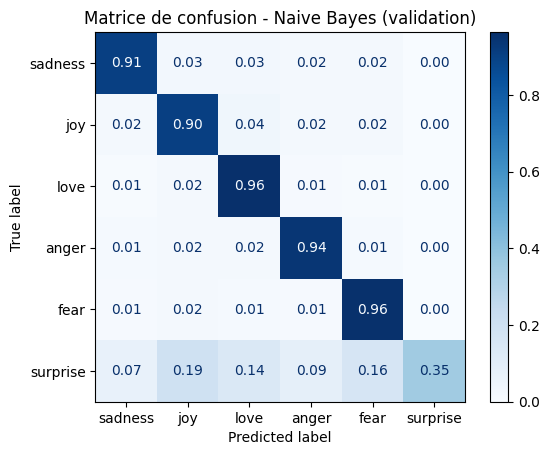

In [73]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_nb,
    display_labels=label_names,
    normalize="true",
    values_format=".2f",
    cmap="Blues"
)
plt.title("Matrice de confusion - Naive Bayes (validation)")
plt.show()

### Résultats de Naive Bayes

Sur la validation, Naive Bayes obtient une accuracy de 0.904 et un F1 macro de 0.830. L'écart entre les deux montre que le modèle est très bon sur certaines émotions mais beaucoup moins sur d'autres.

Sadness, joy, anger et fear sont bien reconnues (F1 entre 0.89 et 0.93). Le gros point faible est surprise, avec un F1 de 0.52. Sa precision est de 0.99 mais son recall n'est que de 0.35 : quand le modèle dit "surprise" il a presque toujours raison, mais il ne retrouve qu'un tiers des vraies surprises. Dans la matrice de confusion, on voit que les surprises ratées partent un peu dans toutes les autres classes, surtout joy (19 %) et fear (16 %). Ça vient du fait que surprise est la classe la plus petite du train (7 857 tweets contre 20 000 pour les autres), et Naive Bayes tient compte de la proportion des classes, donc il la prédit peu. En plus, une surprise peut être positive ou négative, donc elle ressemble à d'autres émotions.

Love a le problème inverse : un recall de 0.96 mais une precision de 0.69, le modèle prédit "love" trop souvent. Les faux love viennent surtout de joy et de sadness. Même si ça ne représente que 3-4 % de ces classes, comme elles sont grosses ça fait environ 900 tweets. C'est un effet de notre sous-échantillonnage : dans le train, love est presque aussi fréquent que les autres classes alors que dans la réalité il ne représente que 6.5 % des tweets.

Naive Bayes est aussi très rapide (quelques secondes pour l'entraînement) et donne directement des probabilités, ce qui est pratique pour la webapp.

In [74]:
# vérifier le surapprentissage de Naive Bayes

y_train_pred_nb = nb.predict(X_train_tfidf)

print(f1_score(y_train, y_train_pred_nb, average="macro"))
print(f1_score(y_val, y_val_pred_nb, average="macro"))

0.9034127999105253
0.8300675784043726


On compare aussi le F1 macro sur le train (0.903) et sur la validation (0.830) pour vérifier le surapprentissage. Il y a environ 7 points d'écart, ce qui reste raisonnable. Une partie vient d'un léger apprentissage "par cœur" (beaucoup de bigrammes rares que le modèle retient), mais une autre partie vient du fait que le train est équilibré alors que la validation garde la vraie répartition des émotions. Sur la validation, les erreurs du type joy → love touchent beaucoup plus de tweets, ce qui fait baisser la precision de love et donc le F1 macro. On peut donc dire que Naive Bayes ne surapprend pas beaucoup.

In [75]:
from sklearn.svm import LinearSVC

svm = LinearSVC(class_weight="balanced", random_state=42)

In [76]:
svm.fit(X_train_tfidf, y_train)

LinearSVC(class_weight='balanced', random_state=42)

In [77]:
y_val_pred_svm = svm.predict(X_val_tfidf)

print(accuracy_score(y_val, y_val_pred_svm))
print(f1_score(y_val, y_val_pred_svm, average="macro"))

0.9655730191680371
0.9562950468745997


In [78]:
print(classification_report(y_val, y_val_pred_svm, target_names=label_names))

              precision    recall  f1-score   support

     sadness       0.98      0.96      0.97     11585
         joy       0.99      0.96      0.97     12915
        love       0.91      0.99      0.95      2434
       anger       0.95      0.97      0.96      5223
        fear       0.94      0.97      0.95      3954
    surprise       0.88      0.99      0.93       982

    accuracy                           0.97     37093
   macro avg       0.94      0.97      0.96     37093
weighted avg       0.97      0.97      0.97     37093



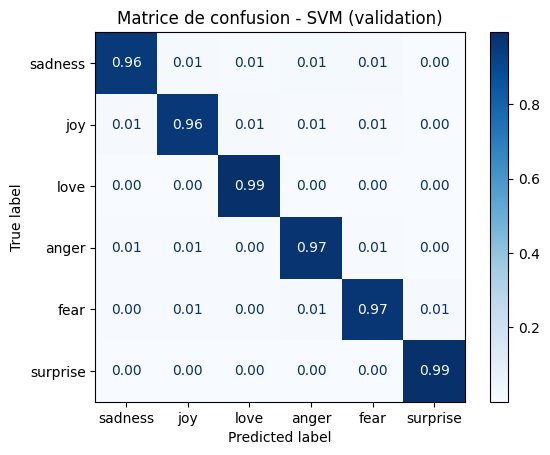

In [79]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_svm,
    display_labels=label_names,
    normalize="true",
    values_format=".2f",
    cmap="Blues"
)
plt.title("Matrice de confusion - SVM (validation)")
plt.show()

### Résultats du SVM

Le SVM fait beaucoup mieux que Naive Bayes sur la validation : 0.966 d'accuracy et 0.956 de F1 macro, contre 0.904 et 0.830 pour Naive Bayes. Surtout, l'écart entre l'accuracy et le F1 macro n'est plus que d'environ 1 point (contre 7 pour Naive Bayes), ce qui veut dire que le modèle est bon sur toutes les émotions et pas seulement sur les grosses classes.

Toutes les émotions ont un F1 au-dessus de 0.93. Le plus gros changement est sur surprise : le recall passe de 0.35 à 0.99, le modèle retrouve presque toutes les surprises. La precision de love passe aussi de 0.69 à 0.91. Ça vient de deux choses. D'abord le paramètre class_weight="balanced", qui donne plus de poids aux erreurs sur les petites classes (surprise a 7 857 tweets dans le train contre 20 000 pour les autres). Ensuite la façon dont le SVM apprend : au lieu de compter les mots par émotion comme Naive Bayes, il cherche les mots qui séparent le mieux les émotions entre elles.

Il y a quand même une contrepartie : pour love et surprise, le recall est à 0.99 mais la precision un peu plus basse (0.91 et 0.88). Le modèle prédit ces émotions un peu trop souvent, et joy et sadness perdent un peu de recall (0.96). C'est l'effet du class_weight : on favorise les petites classes et les grosses en paient un peu le prix. Dans la matrice de confusion, les erreurs restantes sont très faibles (environ 1 % par case) et éparpillées, il n'y a plus de confusion forte entre deux émotions.

In [80]:
# vérifier le surapprentissage du SVM

y_train_pred_svm = svm.predict(X_train_tfidf)

print(f1_score(y_train, y_train_pred_svm, average="macro"))
print(f1_score(y_val, y_val_pred_svm, average="macro"))

0.9992351065756196
0.9562950468745997


Pour le surapprentissage, le SVM obtient un F1 macro de 0.999 sur le train et 0.956 sur la validation, soit environ 4 points d'écart. Le modèle sépare presque parfaitement les tweets du train, il y a donc une part d'apprentissage par cœur, ce qui est assez normal avec autant de colonnes (147 464). Mais le score de validation reste très bon, donc ce qu'il a appris marche aussi sur des tweets qu'il n'a jamais vus. L'écart est même plus petit que pour Naive Bayes (7 points), le SVM généralise mieux.

In [81]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5, metric="cosine", n_jobs=-1)

In [82]:
knn.fit(X_train_tfidf, y_train)

KNeighborsClassifier(metric='cosine', n_jobs=-1)

In [83]:
%%time
y_val_pred_knn = knn.predict(X_val_tfidf)

print(accuracy_score(y_val, y_val_pred_knn))
print(f1_score(y_val, y_val_pred_knn, average="macro"))

0.7388186450273636
0.6950097534714562
CPU times: user 2min 47s, sys: 1min 21s, total: 4min 8s
Wall time: 2min 40s


In [84]:
print(classification_report(y_val, y_val_pred_knn, target_names=label_names))

              precision    recall  f1-score   support

     sadness       0.78      0.78      0.78     11585
         joy       0.86      0.72      0.78     12915
        love       0.49      0.72      0.58      2434
       anger       0.69      0.72      0.71      5223
        fear       0.63      0.75      0.68      3954
    surprise       0.67      0.61      0.64       982

    accuracy                           0.74     37093
   macro avg       0.68      0.72      0.70     37093
weighted avg       0.76      0.74      0.74     37093



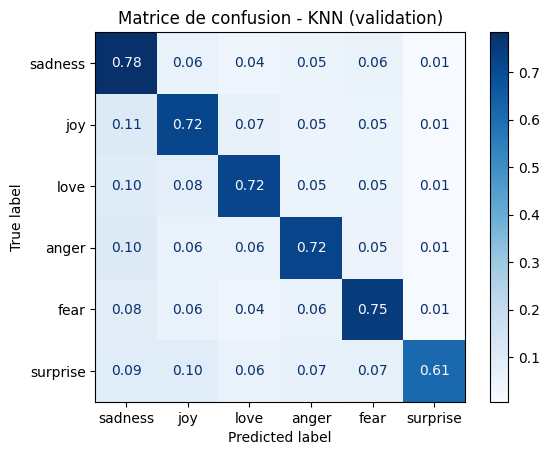

In [85]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_knn,
    display_labels=label_names,
    normalize="true",
    values_format=".2f",
    cmap="Blues"
)
plt.title("Matrice de confusion - KNN (validation)")
plt.show()

### Résultats du KNN

Le KNN est le moins bon des trois modèles : 0.739 d'accuracy et 0.695 de F1 macro sur la validation. Contrairement à Naive Bayes qui avait surtout du mal sur surprise, le KNN est moyen sur toutes les émotions : même les grosses classes comme joy et sadness ne dépassent pas 0.78 de F1. Love est la plus touchée avec une precision de 0.49, le modèle se trompe une fois sur deux quand il prédit love. Surprise est un peu mieux que chez Naive Bayes (0.64 contre 0.52), parce que le KNN ne tient pas compte de la proportion des classes, il fait juste voter les voisins.

Dans la matrice de confusion, les erreurs sont réparties un peu partout (entre 5 et 11 % vers chaque autre émotion), il n'y a pas de confusion logique entre deux émotions proches. On pense que ça vient du fait que le KNN compare les tweets en entier : deux tweets peuvent être "proches" parce qu'ils partagent des mots courants comme "i feel" ou "today", même s'ils n'expriment pas la même émotion. Le SVM, lui, apprend quels mots comptent vraiment pour chaque émotion.

Le KNN est aussi très lent : environ 2 min 40 pour prédire la validation, parce qu'il compare chaque tweet aux 107 325 tweets du train. On n'a pas vérifié son score sur le train pour le surapprentissage, ça aurait pris encore plus de temps et ça n'aurait pas beaucoup de sens : chaque tweet du train se trouverait lui-même comme plus proche voisin.

In [86]:
resultats_ml = pd.DataFrame({
    "modele": ["Naive Bayes", "SVM", "KNN"],
    "accuracy_val": [
        accuracy_score(y_val, y_val_pred_nb),
        accuracy_score(y_val, y_val_pred_svm),
        accuracy_score(y_val, y_val_pred_knn)
    ],
    "f1_macro_val": [
        f1_score(y_val, y_val_pred_nb, average="macro"),
        f1_score(y_val, y_val_pred_svm, average="macro"),
        f1_score(y_val, y_val_pred_knn, average="macro")
    ],
    "f1_macro_train": [
        f1_score(y_train, y_train_pred_nb, average="macro"),
        f1_score(y_train, y_train_pred_svm, average="macro"),
        None
    ]
})

resultats_ml.round(3)

,modele,accuracy_val,f1_macro_val,f1_macro_train
0,Naive Bayes,0.904,0.830,0.903
1,SVM,0.966,0.956,0.999
2,KNN,0.739,0.695,NaN


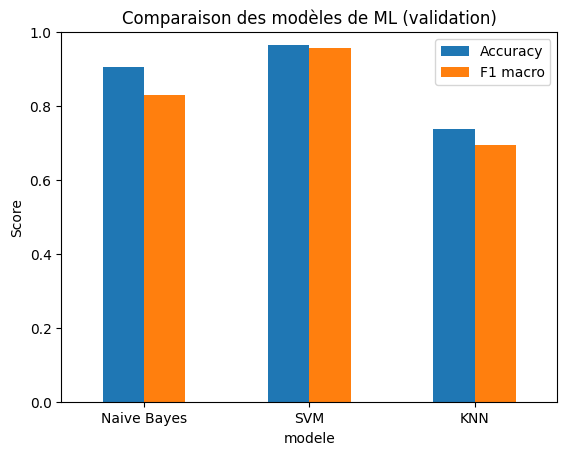

In [87]:
resultats_ml.set_index("modele")[["accuracy_val", "f1_macro_val"]].plot(kind="bar")

plt.title("Comparaison des modèles de ML (validation)")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(["Accuracy", "F1 macro"])
plt.show()

### Comparaison et choix du modèle de ML

On a entraîné les trois modèles sur les mêmes vecteurs TF-IDF et on les a comparés sur la validation.

Le SVM est clairement le meilleur avec un F1 macro de 0.956, devant Naive Bayes (0.830) et le KNN (0.695). C'est aussi le seul qui reconnaît bien toutes les émotions, y compris surprise et love, grâce au class_weight="balanced" et au fait qu'il apprend quels mots séparent le mieux les émotions. Son écart entre train et validation (environ 4 points) montre qu'il généralise bien.

Naive Bayes est très rapide et donne directement des probabilités, mais il rate beaucoup de surprises et prédit love trop souvent. Le KNN est à la fois le moins bon et le plus lent (environ 2 min 40 pour la validation), ce qui ne va pas du tout pour une webapp.

On garde donc le SVM comme modèle de machine learning. Le seul problème, c'est que LinearSVC ne donne pas de probabilités, alors que la webapp doit afficher la probabilité de l'émotion prédite. On règle ça juste après.

In [88]:
from sklearn.calibration import CalibratedClassifierCV

svm_proba = CalibratedClassifierCV(LinearSVC(class_weight="balanced", random_state=42), cv=5)

In [89]:
%%time
svm_proba.fit(X_train_tfidf, y_train)

CPU times: user 18.5 s, sys: 139 ms, total: 18.7 s
Wall time: 16.6 s


CalibratedClassifierCV(cv=5,
                       estimator=LinearSVC(class_weight='balanced',
                                           random_state=42))

In [90]:
y_val_pred_svm_proba = svm_proba.predict(X_val_tfidf)

print(accuracy_score(y_val, y_val_pred_svm_proba))
print(f1_score(y_val, y_val_pred_svm_proba, average="macro"))

0.965869571078101
0.9571017298778165


In [91]:
# voir les probabilités sur quelques phrases

phrases = [
    "i feel so happy today",
    "i am really scared of tomorrow",
    "i can't believe they did this to me",
    "i was shocked when i saw the news"
]

vecteurs = tfidf.transform(phrases)
probas = svm_proba.predict_proba(vecteurs)

pd.DataFrame(probas, columns=label_names, index=phrases).round(2)

,sadness,joy,love,anger,fear,surprise
i feel so happy today,0.02,0.98,0.00,0.00,0.00,0.00
i am really scared of tomorrow,0.00,0.00,0.00,0.00,1.00,0.00
i can't believe they did this to me,0.18,0.03,0.02,0.31,0.45,0.02
i was shocked when i saw the news,0.00,0.00,0.00,0.00,0.00,1.00


### Probabilités du SVM

LinearSVC ne donne pas de probabilités, seulement un score par émotion qui correspond à la distance par rapport à la frontière. Ces scores peuvent être négatifs et ne font pas 1 au total, donc on ne peut pas les afficher comme des probabilités dans la webapp. On a donc utilisé CalibratedClassifierCV, qui apprend à transformer ces scores en probabilités. Avec cv=5, le train est coupé en 5 morceaux : à chaque fois, un SVM est entraîné sur 4 morceaux et la calibration est apprise sur le 5e, que ce SVM n'a pas vu. Au final le modèle fait la moyenne des 5. Tout se passe dans le train, donc la validation et le test ne sont pas touchés.

L'entraînement prend environ 17 secondes et le score sur la validation ne bouge presque pas (F1 macro de 0.957 contre 0.956 sans calibration), donc on garde cette version pour la webapp.

On a testé le modèle sur quelques phrases écrites à la main. Quand la phrase contient un mot d'émotion clair ("happy", "scared", "shocked"), le modèle est quasiment sûr de lui (entre 0.98 et 1.00). Par contre, pour "i can't believe they did this to me", qui n'a aucun mot d'émotion, il hésite entre fear (0.45), anger (0.31) et sadness (0.18). Ça montre une limite du TF-IDF : le modèle se base sur les mots présents et ne comprend pas vraiment le sens de la phrase. C'est logique vu la façon dont le dataset a été construit (les tweets ont sûrement été labellisés à partir de mots-clés), mais ça peut poser problème sur des textes plus naturels. C'est un des points que le deep learning pourrait améliorer.

## Modèle de Deep Learning : RNN

Le SVM donne déjà de très bons résultats, mais on a vu sa limite : il se base sur les mots présents dans le tweet et ne comprend pas vraiment le sens de la phrase. Par exemple "i can't believe they did this to me" ne contient aucun mot d'émotion, et le modèle hésitait entre trois émotions. En plus, avec le TF-IDF, "happy" et "joyful" n'ont aucun rapport.

On a donc testé un réseau de neurones vu en cours, un RNN (réseau de neurones récurrent). Il lit le tweet mot par mot dans l'ordre et garde une mémoire de ce qu'il a déjà lu. On n'utilise plus le TF-IDF : chaque mot reçoit un numéro, puis la première couche du réseau (l'embedding) transforme ce numéro en un vecteur appris pendant l'entraînement. Des mots de sens proche peuvent ainsi finir avec des vecteurs proches.

On garde exactement les mêmes données que pour le ML (train équilibré, validation et test) pour pouvoir comparer. L'entraînement se fait sur le GPU de Colab. On coupe les tweets à 50 mots et on garde un petit modèle, ce qui suffit pour des textes aussi courts. Pour éviter le surapprentissage, on surveille la loss sur la validation à chaque epoch et on arrête l'entraînement quand elle ne s'améliore plus (early stopping).

Au départ on voulait aussi tester un LSTM, mais on s'est arrêté au RNN par manque de temps.

In [92]:
import tensorflow as tf

print(tf.config.list_physical_devices("GPU"))
print(len(X_train), len(X_val), len(X_test))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
107325 37093 37094


In [93]:
from tensorflow.keras.layers import TextVectorization

vectoriseur = TextVectorization(max_tokens=20000, output_sequence_length=50)

In [94]:
vectoriseur.adapt(X_train)

vocabulaire = vectoriseur.get_vocabulary()
print(len(vocabulaire))
print(vocabulaire[:20])

20000
['', '[UNK]', np.str_('i'), np.str_('feel'), np.str_('and'), np.str_('to'), np.str_('the'), np.str_('a'), np.str_('feeling'), np.str_('of'), np.str_('that'), np.str_('my'), np.str_('in'), np.str_('it'), np.str_('like'), np.str_('for'), np.str_('me'), np.str_('so'), np.str_('im'), np.str_('but')]


In [95]:
X_train_seq = vectoriseur(X_train.values).numpy()
X_val_seq = vectoriseur(X_val.values).numpy()
X_test_seq = vectoriseur(X_test.values).numpy()

print(X_train_seq.shape, X_val_seq.shape, X_test_seq.shape)
print(X_train.values[0])
print(X_train_seq[0])

(107325, 50) (37093, 50) (37094, 50)
i feel rather triumphant actually like neener neener you loser you went through the effort of breaking into my car and you got noooothing hahahahahahahaha
[    2     3   188  1265   162    14 18062 18062    31  2553    31   279
   142     6   977     9  1965   105    11   686     4    31   146     1
     1     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0]


In [96]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, Dropout, Dense

tf.keras.utils.set_random_seed(42)

rnn = Sequential([
    Input(shape=(50,)),
    Embedding(input_dim=20000, output_dim=64, mask_zero=True),
    SimpleRNN(64),
    Dropout(0.3),
    Dense(6, activation="softmax")
])

rnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 50, 64)         │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,288,646 (4.92 MB)

 Trainable params: 1,288,646 (4.92 MB)

 Non-trainable params: 0 (0.00 B)

In [97]:
rnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [98]:
from tensorflow.keras.callbacks import EarlyStopping

arret = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)

In [99]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

poids = compute_class_weight(class_weight="balanced", classes=np.arange(6), y=y_train)
poids_classes = dict(enumerate(poids))

print(poids_classes)

{0: np.float64(0.894375), 1: np.float64(0.894375), 2: np.float64(0.9188154920895829), 3: np.float64(0.894375), 4: np.float64(0.894375), 5: np.float64(2.276632302405498)}


In [100]:
historique_rnn = rnn.fit(
    X_train_seq, y_train.values,
    validation_data=(X_val_seq, y_val.values),
    epochs=10,
    batch_size=128,
    class_weight=poids_classes,
    callbacks=[arret]
)

Epoch 1/10
839/839 ━━━━━━━━━━━━━━━━━━━━ 13s 11ms/step - accuracy: 0.7563 - loss: 0.6584 - val_accuracy: 0.9275 - val_loss: 0.2985
Epoch 2/10
839/839 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9493 - loss: 0.1969 - val_accuracy: 0.9258 - val_loss: 0.3074
Epoch 3/10
839/839 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9589 - loss: 0.1530 - val_accuracy: 0.9443 - val_loss: 0.2314
Epoch 4/10
839/839 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9595 - loss: 0.1515 - val_accuracy: 0.9449 - val_loss: 0.2169
Epoch 5/10
839/839 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9521 - loss: 0.1814 - val_accuracy: 0.9434 - val_loss: 0.2358
Epoch 6/10
839/839 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9609 - loss: 0.1472 - val_accuracy: 0.9330 - val_loss: 0.2559


In [101]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

probas_val_rnn = rnn.predict(X_val_seq)
y_val_pred_rnn = probas_val_rnn.argmax(axis=1)

print(accuracy_score(y_val, y_val_pred_rnn))
print(f1_score(y_val, y_val_pred_rnn, average="macro"))

1160/1160 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step
0.9449222225217696
0.9354639049185544


In [102]:
print(classification_report(y_val, y_val_pred_rnn, target_names=label_names))

              precision    recall  f1-score   support

     sadness       0.95      0.95      0.95     11585
         joy       0.98      0.93      0.95     12915
        love       0.86      0.98      0.92      2434
       anger       0.93      0.95      0.94      5223
        fear       0.90      0.96      0.93      3954
    surprise       0.87      0.97      0.92       982

    accuracy                           0.94     37093
   macro avg       0.92      0.96      0.94     37093
weighted avg       0.95      0.94      0.95     37093



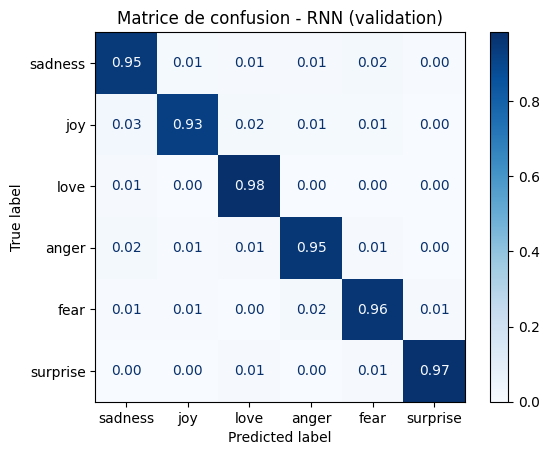

In [103]:
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_pred_rnn,
    display_labels=label_names,
    normalize="true",
    values_format=".2f",
    cmap="Blues"
)
plt.title("Matrice de confusion - RNN (validation)")
plt.show()

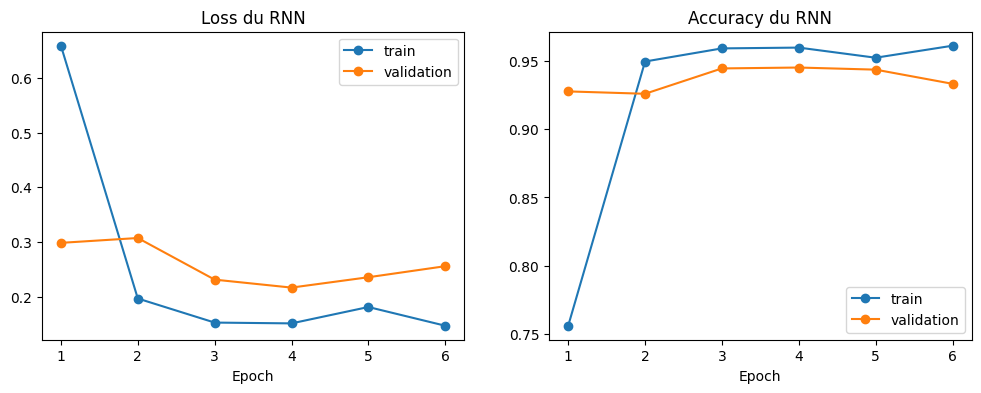

In [104]:
historique = historique_rnn.history
epochs = range(1, len(historique["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, historique["loss"], marker="o", label="train")
axes[0].plot(epochs, historique["val_loss"], marker="o", label="validation")
axes[0].set_title("Loss du RNN")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(epochs, historique["accuracy"], marker="o", label="train")
axes[1].plot(epochs, historique["val_accuracy"], marker="o", label="validation")
axes[1].set_title("Accuracy du RNN")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[0].set_xticks(epochs)
axes[1].set_xticks(epochs)

plt.show()

### Résultats du RNN

Le RNN est composé d'une couche d'embedding (chaque mot devient un vecteur de 64 nombres), d'une couche SimpleRNN qui lit le tweet mot par mot en gardant une mémoire, d'un dropout de 30 % pour limiter le surapprentissage et d'une couche de sortie avec un softmax, qui donne directement les probabilités des 6 émotions. Le modèle a environ 1,3 million de paramètres, dont 99 % dans l'embedding. Comme pour le SVM, on a donné plus de poids aux erreurs sur les petites classes (2,28 pour surprise contre environ 0,9 pour les autres). On a aussi fixé la graine aléatoire avec set_random_seed(42) pour avoir à peu près les mêmes résultats quand on relance le notebook.

L'entraînement est rapide sur GPU, environ 7 secondes par epoch. L'early stopping a arrêté l'entraînement à l'epoch 6 et a gardé les poids de l'epoch 4, qui avait la meilleure loss sur la validation (0.217). Sur les courbes, la loss du train chute dès l'epoch 2 alors que celle de la validation baisse plus lentement jusqu'à l'epoch 4. À l'epoch 5, la loss remonte aussi sur le train : ce n'est pas du surapprentissage, ça montre plutôt que l'apprentissage du SimpleRNN est un peu instable. À l'epoch 6, la loss du train redescend alors que celle de la validation continue de monter, c'est le début du surapprentissage et c'est là que l'entraînement s'arrête. À l'epoch 4 qu'on a gardée, l'écart entre train et validation reste petit (0.960 contre 0.945 d'accuracy).

Sur la validation, le RNN obtient 0.945 d'accuracy et 0.935 de F1 macro. C'est beaucoup mieux que Naive Bayes (0.830) mais un peu en dessous du SVM (0.957). Toutes les émotions ont un F1 entre 0.92 et 0.95, il perd 1 à 3 points par rapport au SVM sur chacune. L'écart le plus marqué est sur love (0.92 contre 0.95), à cause d'une precision de 0.86 : dans la matrice de confusion, 2 % des tweets de joy partent vers love, soit environ 260 tweets. Joy est aussi l'émotion la moins bien retrouvée (recall de 0.93), avec 3 % de ses tweets classés en sadness, environ 390 tweets. C'est bizarre pour deux émotions opposées, ça vient peut-être de phrases avec une négation que le RNN a du mal à garder en mémoire jusqu'au bout. Comme pour le SVM, les petites classes ont un très bon recall (0.98 pour love, 0.97 pour surprise) mais une precision plus basse, c'est l'effet des poids de classes.

Le RNN ne bat donc pas le SVM. On pense que ça vient de deux choses : dans ce dataset l'émotion est souvent portée par un seul mot clé, que le SVM repère très bien, et le SimpleRNN a du mal à garder l'information sur toute la phrase. Un LSTM aurait pu corriger ce deuxième point, mais on ne l'a pas testé par manque de temps.

## Comparaison finale et test

On regroupe les scores de validation des quatre modèles. Pour le SVM, on prend la version calibrée puisque c'est celle qu'on utilisera dans la webapp. Le modèle avec le meilleur F1 macro est ensuite évalué une seule fois sur le jeu de test.

In [105]:
comparaison = pd.DataFrame({
    "modele": ["Naive Bayes", "SVM", "KNN", "RNN"],
    "accuracy_val": [
        accuracy_score(y_val, y_val_pred_nb),
        accuracy_score(y_val, y_val_pred_svm_proba),
        accuracy_score(y_val, y_val_pred_knn),
        accuracy_score(y_val, y_val_pred_rnn)
    ],
    "f1_macro_val": [
        f1_score(y_val, y_val_pred_nb, average="macro"),
        f1_score(y_val, y_val_pred_svm_proba, average="macro"),
        f1_score(y_val, y_val_pred_knn, average="macro"),
        f1_score(y_val, y_val_pred_rnn, average="macro")
    ]
})

comparaison.round(3).sort_values("f1_macro_val", ascending=False)

,modele,accuracy_val,f1_macro_val
1,SVM,0.966,0.957
3,RNN,0.945,0.935
0,Naive Bayes,0.904,0.830
2,KNN,0.739,0.695


In [106]:
y_test_pred_svm = svm_proba.predict(X_test_tfidf)

print(accuracy_score(y_test, y_test_pred_svm))
print(f1_score(y_test, y_test_pred_svm, average="macro"))

0.9650886935892597
0.9572546230913491


In [107]:
print(classification_report(y_test, y_test_pred_svm, target_names=label_names))

              precision    recall  f1-score   support

     sadness       0.98      0.96      0.97     11585
         joy       0.98      0.96      0.97     12916
        love       0.91      0.99      0.95      2433
       anger       0.95      0.97      0.96      5224
        fear       0.94      0.97      0.96      3954
    surprise       0.91      0.98      0.94       982

    accuracy                           0.97     37094
   macro avg       0.94      0.97      0.96     37094
weighted avg       0.97      0.97      0.97     37094



## Conclusion

On a comparé quatre modèles sur la validation : trois modèles de machine learning avec un TF-IDF (Naive Bayes, SVM, KNN) et un réseau de neurones récurrent (RNN). Le SVM est le meilleur avec un F1 macro de 0.957, devant le RNN (0.935), Naive Bayes (0.830) et le KNN (0.695). Il est aussi rapide à entraîner (moins de 20 secondes avec la calibration) et rapide pour prédire, ce qui compte pour la webapp. On a donc choisi le SVM calibré comme modèle final.

On l'a évalué une seule fois sur le jeu de test, que les modèles n'avaient jamais vu. Il obtient 0.965 d'accuracy et 0.957 de F1 macro, quasiment les mêmes scores que sur la validation, et toutes les émotions ont un F1 entre 0.94 et 0.97. Le choix du modèle est donc confirmé, son score de validation n'était pas dû au hasard.

Le modèle a quand même des limites. Il se base sur les mots présents dans le texte et ne comprend pas vraiment le sens de la phrase : il est très sûr de lui quand le tweet contient un mot d'émotion clair, mais il hésite sur des phrases sans mot d'émotion. C'est lié au dataset, dont les tweets ont sûrement été labellisés automatiquement à partir de mots-clés, donc les résultats seraient sûrement moins bons sur des textes plus naturels. Il ne marche aussi qu'en anglais, et à cause des poids donnés aux petites classes, il prédit love et surprise un peu trop souvent (precision autour de 0.91).

Pour aller plus loin, on aurait pu tester un LSTM, qui garde mieux l'information sur toute la phrase que le SimpleRNN, ou un modèle pré-entraîné comme DistilBERT, qui connaît déjà l'anglais et gérerait sûrement mieux les phrases sans mot d'émotion. On aurait aussi pu régler les hyperparamètres du SVM (le paramètre C) ou adoucir les poids des classes pour mieux équilibrer precision et recall.